In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint
import pickle

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.14.6 (main, Jun 10 2026, 18:54:31) [GCC 15.2.0]


In [2]:
def plot_params(lfm, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    # ax.plot((0,0), (mod.n_param,0), ls='--', lw=0.5, color='b')
    n = lfm.n_input
    mask = np.zeros(n, np.uint8)
    for mod in lfm.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        mask = mask | (abs(param1) > p_threshold)
        ax.vlines(range(mod.n_input), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'#(abs(param) > {p_threshold}) = {s}')

def plot_param(mod, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = mod.n_input
    param1 = np.asarray(mod.param[1:])
    # print(param1[0])
    param_p = param1.copy()
    param_m = param1.copy()
    param_p[param1 < 0] = 0
    param_m[param1 > 0] = 0
    mask = (abs(param1) > p_threshold)
    ax.vlines(range(mod.n_input), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'#(abs(param) > {p_threshold}) = {s}')

In [3]:
path = f"/home/intellimath/YD/repos/spectra/20"
options = {}
dd = {}
# widgets.load_spectra(path, dd, options)

In [4]:
dd = io.load_spectra(path, {"вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["20"], 
                            "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })

In [5]:
dd.align_bottom()
dd.crop(300)
# dd.scale_by_mean()

In [6]:
dd.drop_zeros_spectrum()
dd.drop_notfinite()
dd.drop_empty()
dd.isfinite()

In [7]:
dd.despike(2.0)

In [8]:
dd.denoise_svd()

In [9]:
dd.robust_averaging()

In [10]:
dd.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__20_3_1…

In [10]:
# dd.select_baselines( tau2=1.0e4,     
#                       func=funcs.RStep(0.05, 0.002),
#                       # func2=funcs.RStep(0.001, 0.001),
#                       func2_e=inventory.relative_abs_max,
#                       # verbose=False,
# )

In [10]:
dd.isfinite
dd.drop_notfinite()
dd.drop_zeros_spectrum()

In [11]:
dd.filter()

In [12]:
dd.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__20_3_1…

In [13]:
# dd.select_baselines(tau2=1.0e3, #tau1=-1.0e-3,
#                       func=funcs.RStep(0.0, 0.002),
#                       # func2=funcs.RStep(0.001, 0.001),
#                       func2_e=inventory.relative_abs_max,
#                       # verbose=False,
# )

In [14]:
dd.subtract_baselines(tau2=1.0e3, #tau1=-1.0e-3,
                      func=funcs.RStep(0.01, 0.001),
                      # func2=funcs.RStep(0.0, 0.001),
                      func2_e=inventory.relative_abs_max,
                      # verbose=False,
                     )

FloatProgress(value=0.0, bar_style='success', description='SA_97__20_3_1_1_термический_20260622_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__20_3_1_2_термический_20260622_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__20_3_1_3_термический_20260622_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__20_4_1_1_термический_20260625_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__20_4_1_2_термический_20260625_super_SE__H2O(…

...

FloatProgress(value=0.0, bar_style='success', description='SS_17__20_4_1_2_термический_20260625_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__20_4_1_3_термический_20260625_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__20_5_1_1_термический_20260629_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__20_5_1_2_термический_20260629_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__20_5_1_3_термический_20260629_super_SE__H2O(…

In [15]:
dd.scale_by_mean()

In [16]:
dd.filter()

In [18]:
# dd.despike(2.0)

In [18]:
dd.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__20_3_1…

In [17]:
dd.save("/home/intellimath/work/spectra/20_termo", "rm_bl")

In [3]:
dd2 = spectra.SpectraCollection()
dd2.load("/home/intellimath/work/spectra/20_termo", "rm_bl")

In [21]:
# dd2.plot_spectra(True, kind="despike")

In [22]:
# dd2 = dd

In [4]:
dd_SA = dd2.subcollection_by_attr_value("вид_бактерий", "SA")
dd_SS = dd2.subcollection_by_attr_value("вид_бактерий", "SS")
dd_SH = dd2.subcollection_by_attr_value("вид_бактерий", "SH")

# dd_SA.denoise_svd()
# dd_SS.denoise_svd()
# dd_SH.denoise_svd()

Ys_SA = dd_SA.union_y()
Ys_SS = dd_SS.union_y()
Ys_SH = dd_SH.union_y()
Ys = dd2.union_y()
xs = dd2.same_x()
print(len(Ys_SA), len(Ys_SS), len(Ys_SH))


169 171 170


In [27]:
dd_SH.flatten()

In [28]:
dd_SH.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SH_15__20_3_1…

In [25]:
# dd_SH.plot_pca_spectra_all(5)

In [ ]:
c, As, Ls = pca.find_loc_and_pc_l2_lq(Ys, 5, 1.5)
U = (Ys - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

plt.figure(figsize=(12,5))
for i,a in enumerate(As):
    plt.plot(a, label=str(i+1))
plt.minorticks_on()
plt.grid(lw=0.5, ls=':')
plt.legend()
plt.show()

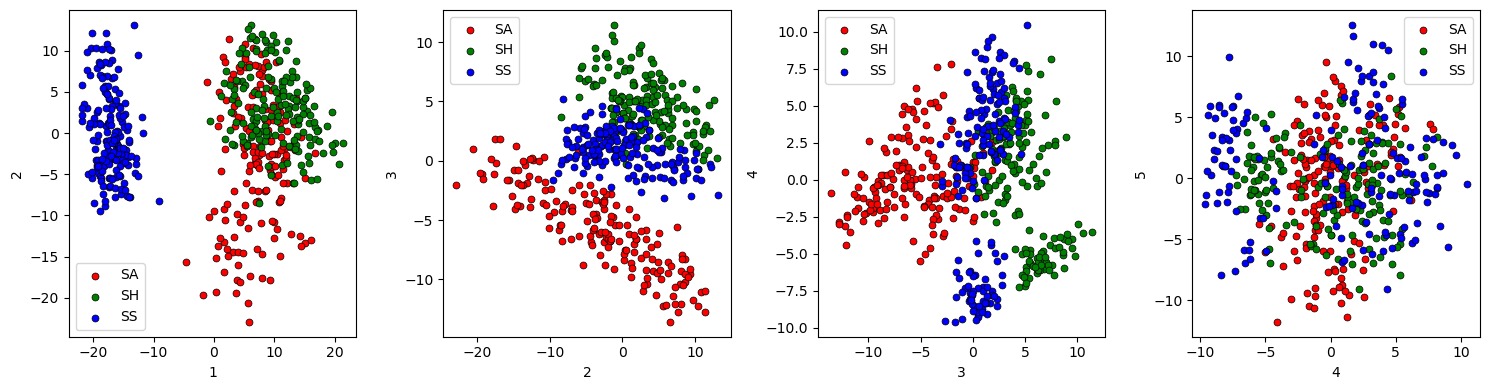

In [20]:
c, As, Ls = pca.find_loc_and_pc(Ys, 5)
U = (Ys - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

# plt.figure(figsize=(10,3))
# plt.plot(Ls/Ls.sum(), marker='o')
# plt.grid(ls=':', lw=0.5)
# plt.minorticks_on()
# plt.show()

In [30]:
# dd2.plot_spectra()

In [5]:
import mlgrad.models as models
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss

import mlgrad.regr as regr
import mlgrad.af as af

Zs_SS = np.ones(Ys_SS.shape[0])
Zs_SH = np.ones(Ys_SH.shape[0])
Zs_SA = np.ones(Ys_SA.shape[0])

ys = np.concatenate((Ys_SS, Ys_SH, Ys_SA), axis=0)
zs = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA), axis=0)

ys1 = np.concatenate((Ys_SS,Ys_SH), axis=0)
zs1 = np.concatenate((Zs_SS,-Zs_SH), axis=0)
ys1 = np.ascontiguousarray(ys1)
zs1 = np.ascontiguousarray(zs1)

ys2 = np.concatenate((Ys_SH,Ys_SA), axis=0)
zs2 = np.concatenate((Zs_SH,-Zs_SA), axis=0)
ys2 = np.ascontiguousarray(ys2)
zs2 = np.ascontiguousarray(zs2)

ys3 = np.concatenate((Ys_SA,Ys_SS), axis=0)
zs3 = np.concatenate((Zs_SA,-Zs_SS), axis=0)
ys3 = np.ascontiguousarray(ys3)
zs3 = np.ascontiguousarray(zs3)

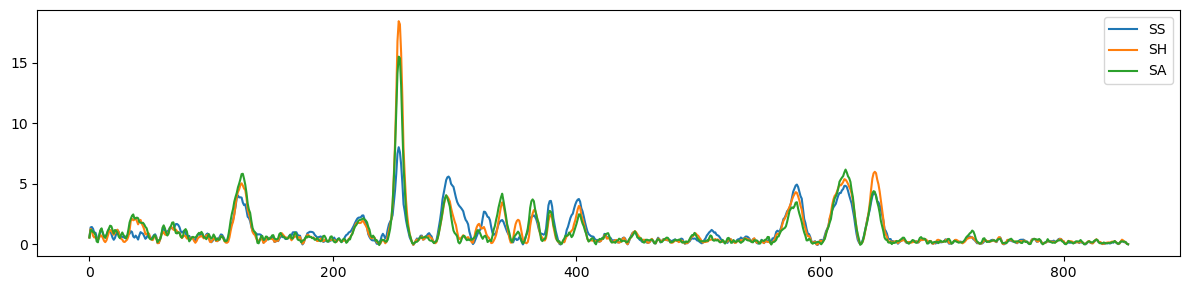

In [22]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
import joblib
import sys

def fit_lm(ys, zs, tau=0, accuracy_min=0.75, n_try=5, sigma=1.0, p_threshold=1.0e-4):
    Np = (zs>0).sum()
    Nm = (zs<0).sum()
    N = Np + Nm
    
    weights = np.zeros(N)
    weights[zs > 0] = Nm / N
    weights[zs < 0] = Np / N

    mod = models.LinearModel(ys.shape[1])
    mod.allocate()
    mod.init_param()
    if p_threshold != 0:
        mod.use_regularizer(funcs2.AbsoluteNorm(1), tau)
    else:
        mod.use_eqn(funcs2.AbsoluteNorm(1), tau)

    if p_threshold != 0:
        projector = gd.Masked(mod, p_threshold)
    else:
        projector = gd.L1Projector(1)

    for i in range(n_try):
        mod.init_param()

        alg = regr.regression(ys, zs, mod,
                              loss_func=loss.MarginLoss(funcs.Hinge(1)),
                              projector=projector, 
                              weights=weights,
                              h=0.002, n_iter=1000)
        w = accuracy_score(zs, np.sign(mod.evaluate(ys)))
        # sys.stdout.write(f"{w} {(mod.ob_param > 0).sum()}, ")
        # sys.stdout.flush()
        if w >= accuracy_min:
            break
    # sys.stdout.write("\n")
    return mod, w

@joblib.delayed
def fit_snm(ys, zs, weights, tau=0, accuracy_min=0.75, n_try=5, sigma=1.0, p_threshold=1.0e-4):
    mod = models.SigmaNeuronModel(funcs.Sigmoidal(sigma), ys.shape[1])
    mod.allocate()
    mod.init_param()
    mod.use_regularizer(funcs2.AbsoluteNorm(), tau)

    if p_threshold != 0:
        projector = gd.Masked(mod, p_threshold)
    else:
        projector = None

    for i in range(n_try):
        mod.init_param()

        alg = regr.regression(ys, zs, mod,
                              loss_func=loss.ErrorLoss(funcs.SoftAbs_Sqrt(0.1)),
                              # loss_func=loss.ErrorLoss(funcs.Abs()),
                              # regnorm=funcs2.AbsoluteNorm(),
                              projector=projector, 
                              weights=weights,
                              h=0.005, n_iter=1000)
        w = accuracy_score(zs, np.sign(mod.evaluate(ys)))
        # sys.stdout.write(f"{w} {(mod.ob_param > 0).sum()}, ")
        # sys.stdout.flush()
        if w >= accuracy_min:
            break
    # sys.stdout.write("\n")
    return mod, w

def fit_lfm(ys, zs, tau=0, *, n_model=45, accuracy_min=0.75, n_try=5, sigma=1.0, p_threshold=1.0e-4):
    Np = (zs>0).sum()
    Nm = (zs<0).sum()
    N = Np + Nm
    
    weights = np.zeros(N)
    weights[zs > 0] = Nm / N
    weights[zs < 0] = Np / N

    with joblib.Parallel(n_jobs=4, max_nbytes=None) as parallel:
        results = parallel(
            fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma)
            for i in range(n_model)
        )

    lfm = models.LinearFuncModel()
    for mod, w in results:
    # for i in range(n_model):
    #     mod, w = fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma, p_threshold=p_threshold)
        lfm.add(mod, w)

    inventory.normalize(lfm.weights.asarray())
    return lfm

In [17]:
lm1, _ = fit_lm(ys1, zs1, tau=100, p_threshold=1.0e-4)
print(accuracy_score(zs1, np.sign(lm1.evaluate(ys1))))

1.0


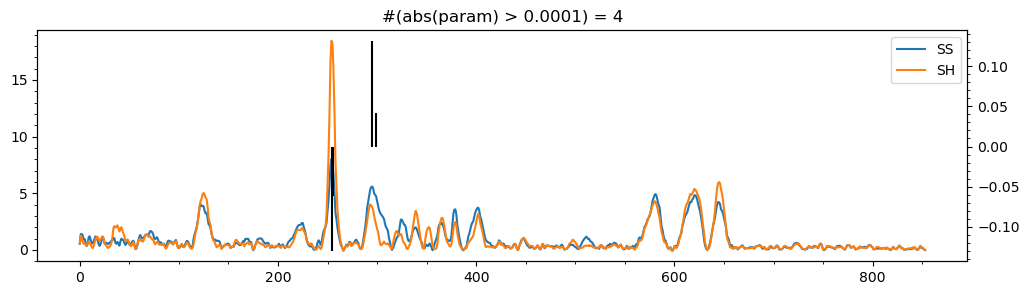

In [18]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.minorticks_on()
plt.legend()
plot_param(lm1)
plt.show()
# print(np.asarray(lfm1.models[0].param))

#### SS/SH

In [142]:
lfm1 = fit_lfm(ys1, zs1, tau=250.0)
print(accuracy_score(zs1, np.sign(lfm1.evaluate(ys1))))

1.0


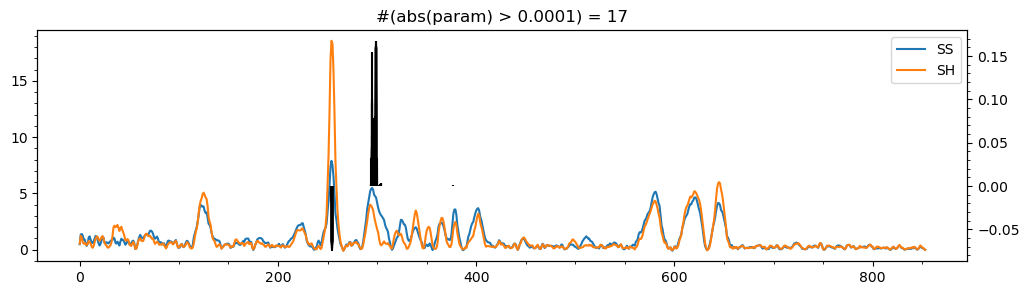

In [143]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.minorticks_on()
plt.legend()
plot_params(lfm1)
plt.show()
# print(np.asarray(lfm1.models[0].param))

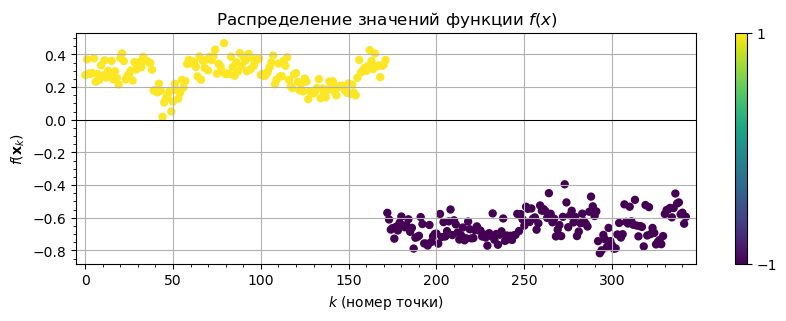

In [144]:
plt.figure(figsize=(10,3))
plots.plot_cls_function(lfm1, ys1, zs1)

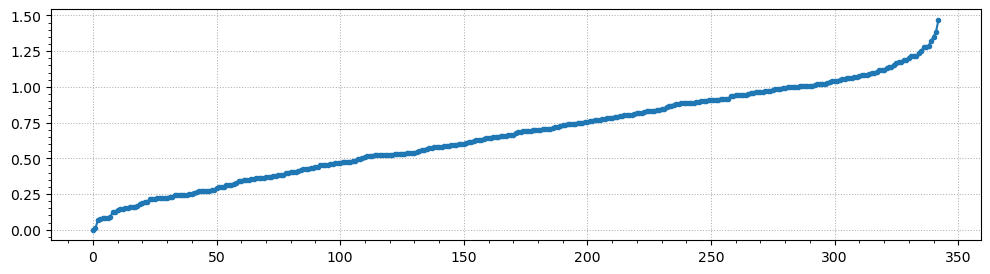

In [145]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs1*lfm1.evaluate(ys1)))), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

### SH SA

In [162]:
lfm2 = fit_lfm(ys2, zs2, tau=120.0)
print(accuracy_score(zs2, np.sign(lfm2.evaluate(ys2))))

0.967551622418879


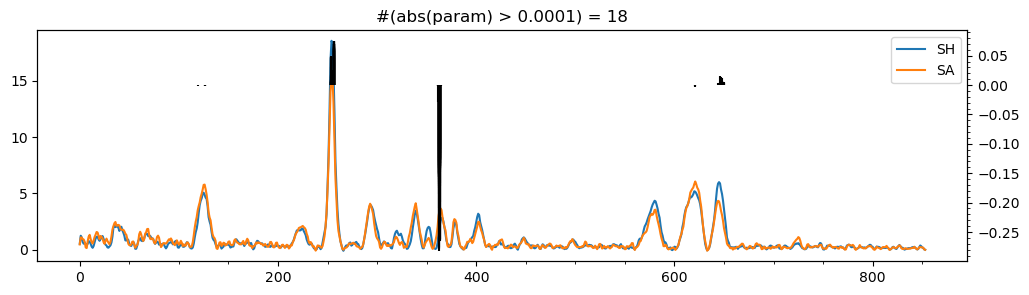

In [163]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plot_params(lfm2)
plt.show()

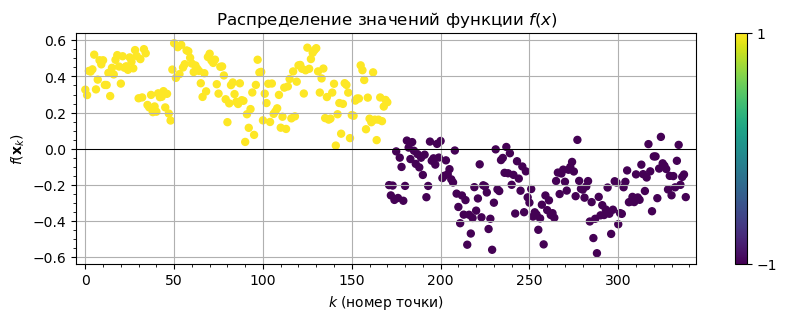

In [164]:
plt.figure(figsize=(10,3))
plots.plot_cls_function(lfm2, ys2, zs2)

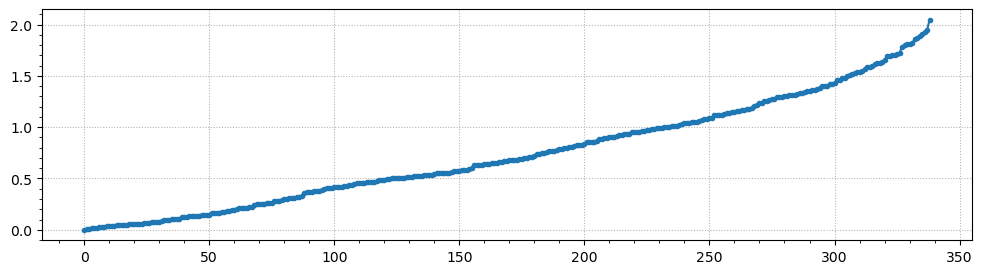

In [165]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs2*lfm2.evaluate(ys2)))), marker='o', ms=3)
# plt.plot(sorted(zs2*lfm2.evaluate(ys2)), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

### SA SS

In [174]:
lfm3 = fit_lfm(ys3, zs3, tau=250.0)
print(accuracy_score(zs3, np.sign(lfm3.evaluate(ys3))))

1.0


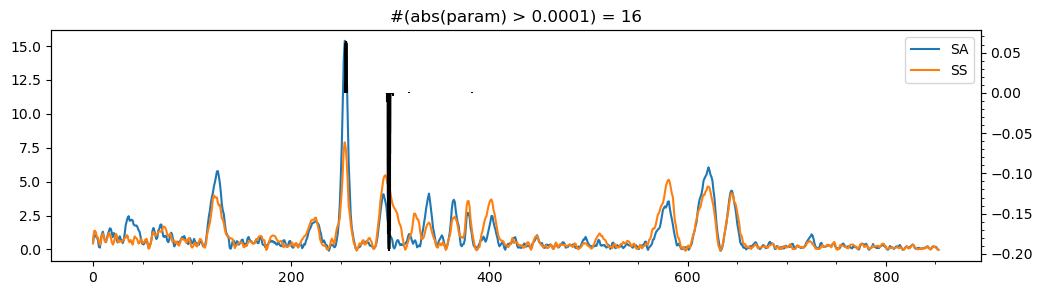

In [175]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.legend()
plot_params(lfm3)
plt.show()

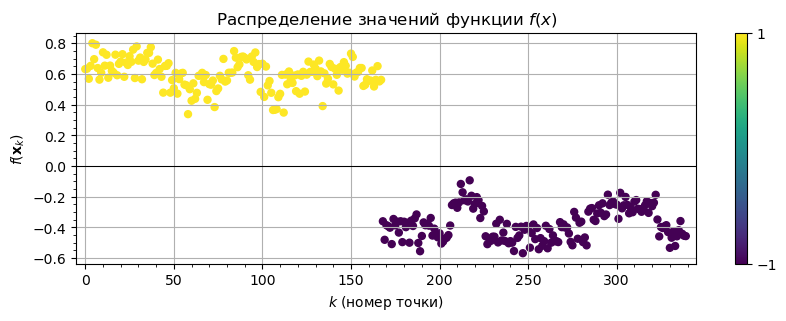

In [176]:
plt.figure(figsize=(10,3))
plots.plot_cls_function(lfm3, ys3, zs3)

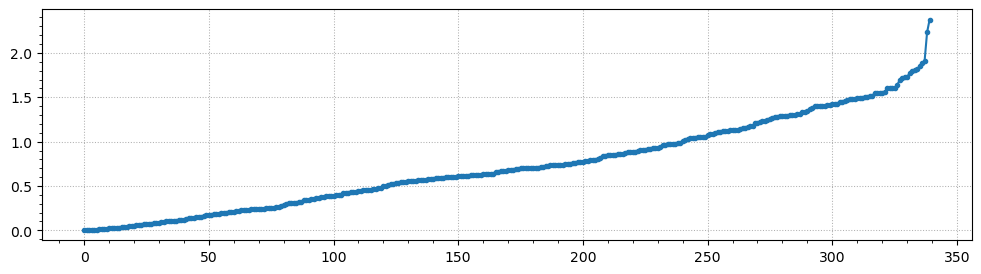

In [177]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs3*lfm3.evaluate(ys3)))), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

In [178]:
with open("lfm_20_term.pickle", "wb") as f:
    pickle.dump([lfm1, lfm2, lfm3], f)

In [179]:
with open("lfm_20_term.pickle", "rb") as f:
    lfm1, lfm2, lfm3 = pickle.load(f)


511
172
182
3


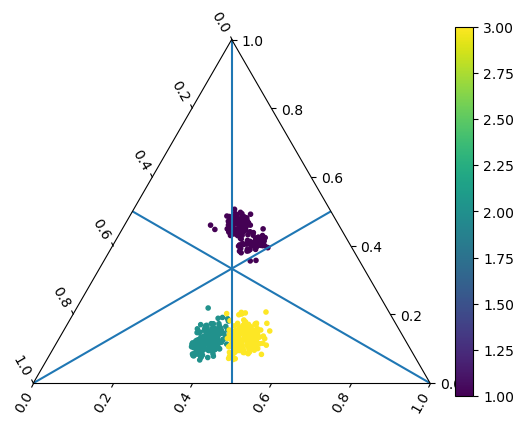

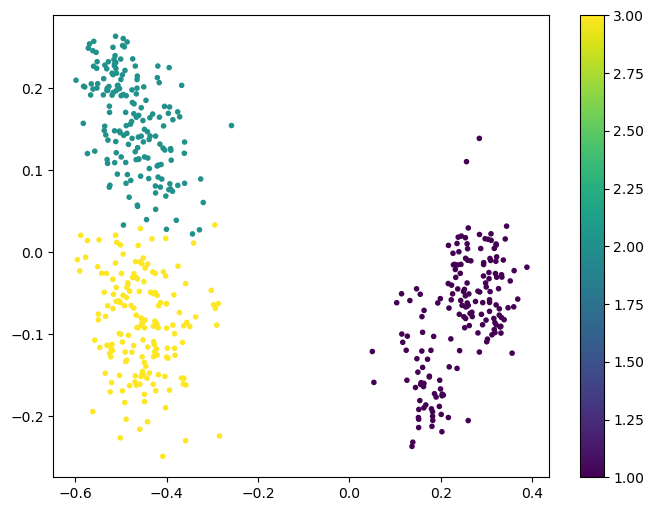

In [180]:
import mpltern
print(len(ys))

ax = plt.subplot(projection="ternary")
Z1 = lfm1.evaluate(ys)
Z2 = lfm2.evaluate(ys)
Z3 = lfm3.evaluate(ys)
Y1 = (1 + (Z1 - Z3) / 2) / 2
Y2 = (1 + (Z2 - Z1) / 2) / 2
Y3 = (1 + (Z3 - Z2) / 2) / 2
Y1[Y1<0] = 0
Y2[Y2<0] = 0
Y3[Y3<0] = 0
print(((Z1>0) & (Z3<0)).sum())
print(((Z2>0) & (Z1<0)).sum())
print(((Z2>0) & (Z3<0)).sum())
# print(Y1)
# print(Y2)
# print(Y3)
C = [(y1,y2,y3) for y1,y2,y3 in zip(Y1,Y2,Y3)]
# cax = ax.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax.transAxes)
cs = ax.scatter(Y1, Y2, Y3, c=zs, s=9)
plt.colorbar(cs)
ax.axline(
    [0.5, 0.0, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.5, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.0, 0.5],
    [0.5, 0.5, 0.5])
plt.show()

zz1 = Y1
zz2 = Y2 * np.exp(2j/3 * np.pi)
zz3 = Y3 * np.exp(-2j/3 * np.pi)
C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
plt.figure(figsize=(8,6))
cs = plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=9, c=C)
plt.colorbar(cs)
plt.show()


In [98]:
from sklearn.linear_model import LogisticRegression

XX = np.c_[np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3)]
YY = np.concatenate((Zs_SS-1, Zs_SH, 2*Zs_SA))

lrg = LogisticRegression()
lrg.fit(XX, YY)
print(accuracy_score(YY, lrg.predict(XX)))

1.0


In [99]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
def plot_confusion_matrix(Y, Yp, labels): #, Y_test, Z, Z_test):
    cm = confusion_matrix(Y, Yp, normalize="true")
    plt.figure(figsize=(4,3))
    ax = sns.heatmap(cm, annot=True, cmap='YlGnBu', fmt='0.2f',
                     xticklabels=labels, yticklabels=labels, cbar=False)
    ax.xaxis.tick_top()
    plt.xticks(rotation=90) 
    plt.show()


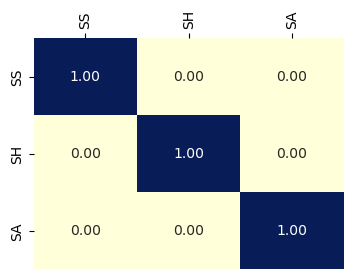

In [100]:
plot_confusion_matrix(YY, lrg.predict(XX), labels=["SS", "SH", "SA"])

In [101]:
path = f"/home/intellimath/YD/repos/spectra/21_SU"
dd_test = io.load_spectra(path, { #"вид_бактерий":["A", "B", "C", "D"], 
                            # "номер_цикла":["1"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],                            
                           }, verbose=False)

In [102]:
dd_test.align_bottom()
dd_test.crop(300)
# dd_test.scale_by_mean()

In [103]:
dd_test.filter()

In [104]:
dd_test.drop_zeros_spectrum()
dd_test.drop_notfinite()
dd_test.drop_empty()
dd_test.isfinite()

In [105]:
dd.despike(2.0)

In [106]:
dd.denoise_svd()

In [107]:
dd_test.robust_averaging()

In [86]:
# dd_test.despike(2.0)

In [87]:
# dd_test.denoise_svd()

In [108]:
dd_test.isfinite
dd_test.drop_notfinite()
dd_test.drop_zeros_spectrum()

In [109]:
# dd.scale_by_max()
# dd_test.scale_by_mean()

In [110]:
dd_test.filter()

In [58]:
# dd2_test.select_baselines(tau2=1.0e3, #tau1=-0.0001,
#                      func=funcs.RStep(0.0, 0.002), 
#                      func2_e=inventory.relative_abs_max,                     
#                     )

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('A_no date__18…

In [111]:
dd_test.subtract_baselines(tau2=1.0e3, #tau1=-0.001,
                      func=funcs.RStep(0.01, 0.002),
                      func2_e=inventory.relative_abs_max,
                     )
dd_test.scale_by_mean()

FloatProgress(value=0.0, bar_style='success', description='SU11___21_Test__1_термический_20260706_super_SE__H2…

FloatProgress(value=0.0, bar_style='success', description='SU12___21_Test__1_термический_20260706_super_SE__H2…

FloatProgress(value=0.0, bar_style='success', description='SU13___21_Test__1_термический_20260706_super_SE__H2…

FloatProgress(value=0.0, bar_style='success', description='SU14___21_Test__1_термический_20260706_super_SE__H2…

FloatProgress(value=0.0, bar_style='success', description='SU15___21_Test__1_термический_20260706_super_SE__H2…

...

FloatProgress(value=0.0, bar_style='success', description='SU72___21_Test__1_термический_20260714_super_SE__H2…

FloatProgress(value=0.0, bar_style='success', description='SU75___21_Test__1_термический_20260714_super_SE__H2…

FloatProgress(value=0.0, bar_style='success', description='SU79___21_Test__1_термический_20260714_super_SE__H2…

FloatProgress(value=0.0, bar_style='success', description='SU7___21_Test__1_термический_20260703_super_SE__H2O…

FloatProgress(value=0.0, bar_style='success', description='SU80___21_Test__1_термический_20260714_super_SE__H2…

In [112]:
dd_test.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SU11___21_Tes…

In [181]:
keys = list(dd_test.keys())
# cls_names = [key.split("_")[0] for key in keys]
@ipywidgets.interact(key=keys)
def plot_cls(key):
    dd_key = dd_test[key]
    Ys_A = dd_key.y

    # print("1:SS 2:SH 3:SA")

    Z1_A = lfm1.evaluate(Ys_A)
    Z2_A = lfm2.evaluate(Ys_A)
    Z3_A = lfm3.evaluate(Ys_A)
    Y1_A = (1 + (Z1_A - Z3_A) / 2) / 2
    Y2_A = (1 + (Z2_A - Z1_A) / 2) / 2
    Y3_A = (1 + (Z3_A - Z2_A) / 2) / 2
    Y1_A[Y1_A<0] = 0
    Y2_A[Y2_A<0] = 0
    Y3_A[Y3_A<0] = 0
    zz1_A = Y1_A
    zz2_A = Y2_A * np.exp(2j/3 * np.pi)
    zz3_A = Y3_A * np.exp(-2j/3 * np.pi)
    XX_A = np.c_[np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A)] 

    C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
    plt.figure(figsize=(9,5))
    xx, yy = np.meshgrid(np.linspace(-0.8, 0.8, 100), np.linspace(-0.7, 0.7, 100))
    xy = np.c_[xx.ravel(), yy.ravel()]
    zz = lrg.predict(xy)
    zz = zz.reshape(xx.shape)
    plt.imshow(zz, alpha=0.2, cmap=plt.cm.rainbow, extent=(-0.8,0.8,-0.8,0.8), origin="lower")
    
    cs=plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=16, c=C)
    plt.colorbar(cs, ticks=[1,2,3])
    plt.scatter(np.real(zz1_A+zz2_A+zz3_A), np.imag(zz1_A+zz2_A+zz3_A), s=16, marker='x', c="brown", label="test")
    # plt.scatter(np.real(zz1_B+zz2_B+zz3_B), np.imag(zz1_B+zz2_B+zz3_B), s=16, marker='x', c="green", label="B")
    # plt.scatter(np.real(zz1_C+zz2_C+zz3_C), np.imag(zz1_C+zz2_C+zz3_C), s=16, marker='x', c="magenta", label="C")
    # plt.scatter(np.real(zz1_D+zz2_D+zz3_D), np.imag(zz1_D+zz2_D+zz3_D), s=15, marker='x', c="red", label="D")
    plt.legend()
    plt.text(-0.4,-0.4, "SA")
    plt.text(0.4,-0.4, "SS")
    plt.text(-0.4,0.4, "SH")
    plt.show()
    

interactive(children=(Dropdown(description='key', options=('SU11___21_Test__1_термический_20260706_super_SE__H…